# Forecasting data and training exploration


This section explores training data only: the intersection of both training ranges in `split_scope_v1` (Unseen-subject Generalization training subjects, restricted to their Within-subject Future Prediction training period).

Minute rows are autocorrelated and nested within subjects, so statistics are formed within subject first and then described across subjects. Correlations are hypothesis generating only.

Only the shared training scope contributes to the EDA.

In [1]:
# --- Import dependencies and configure artifact paths ---

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.paths import PROJECT_ROOT
from src.windows import assign_splits, build_windows
AUDIT_DIR = PROJECT_ROOT / "results" / "data_quality"
CLEAN_DIR = PROJECT_ROOT / "results" / "aligned_data"
FORECAST_DIR = PROJECT_ROOT / "results" / "forecast_windows"
FORECAST_DIR.mkdir(parents=True, exist_ok=True)

# --- Configure deterministic displays and figures ---

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
FIGURE_METADATA = {"Software": None}

In [2]:
# Load the development/test isolation table produced by data audit.
split_scope = pd.read_csv(
    AUDIT_DIR / "split_scope_v1.csv",
    parse_dates=["start_time", "end_time", "protocol_a_train_end_time",
                 "protocol_a_val_end_time", "common_training_range_end_time"],
)

# The exploratory scope is the intersection of both training ranges:
# Protocol B training subjects only, and only their Protocol A training period.
eda_scope = split_scope.loc[
    split_scope["common_training_range_available"],
    ["subject_id", "start_time", "common_training_range_end_time", "protocol_b_group"],
].rename(columns={"subject_id": "subject", "start_time": "scope_start",
                  "common_training_range_end_time": "scope_end"}).reset_index(drop=True)

excluded_subjects = set(split_scope.loc[~split_scope["common_training_range_available"], "subject_id"])
training_subjects = set(eda_scope["subject"])

# Leakage guards: no Protocol B validation/test subject may enter the exploratory scope.
assert eda_scope["protocol_b_group"].eq("train").all()
assert training_subjects.isdisjoint(excluded_subjects)
assert eda_scope["scope_end"].notna().all()

print(f"Subjects in the exploratory training scope (Protocol B train): {len(training_subjects)}")


Subjects in the exploratory training scope (Protocol B train): 27


In [3]:
# Load only the aligned 1-minute columns needed for glucose and meal exploration.
dynamic_columns = [
    "subject", "timestamp", "libre_gl", "dexcom_gl",
    "is_published_source_row", "is_inserted_grid_row", "gap_id",
]
aligned = pd.read_parquet(CLEAN_DIR / "dynamic_aligned_1min.parquet", columns=dynamic_columns)
aligned = aligned.merge(eda_scope[["subject", "scope_start", "scope_end"]], on="subject", how="inner")
aligned = aligned.loc[
    aligned["timestamp"].between(aligned["scope_start"], aligned["scope_end"])
].drop(columns=["scope_start", "scope_end"]).sort_values(["subject", "timestamp"]).reset_index(drop=True)

# Row shifts are later used as minute lags, so the scoped grid must stay contiguous at 1 minute.
minute_steps = aligned.groupby("subject")["timestamp"].diff().dropna()
assert minute_steps.eq(pd.Timedelta(minutes=1)).all()
assert set(aligned["subject"]) == training_subjects

scope_summary = aligned.groupby("subject").agg(
    scope_start=("timestamp", "min"),
    scope_end=("timestamp", "max"),
    grid_minutes=("timestamp", "size"),
    published_rows=("is_published_source_row", "sum"),
    inserted_rows=("is_inserted_grid_row", "sum"),
).reset_index()
scope_summary["scope_days"] = (
    (scope_summary["scope_end"] - scope_summary["scope_start"]).dt.total_seconds() / 86400
).round(2)

print(f"Aligned grid rows in the training scope: {len(aligned):,}")
print(scope_summary[["grid_minutes", "published_rows", "inserted_rows", "scope_days"]].describe().round(1).to_string())

Aligned grid rows in the training scope: 248,739
       grid_minutes  published_rows  inserted_rows  scope_days
count          27.0            27.0           27.0        27.0
mean         9212.6          9211.4            1.1         6.4
std           770.0           770.8            4.0         0.5
min          8235.0          8235.0            0.0         5.7
25%          8689.5          8689.5            0.0         6.0
50%          8856.0          8856.0            0.0         6.2
75%          9684.0          9684.0            0.0         6.7
max         11241.0         11241.0           15.0         7.8


In [4]:
# Subject-level background variables for the training subjects only.
bio = pd.read_parquet(CLEAN_DIR / "bio_canonical.parquet")
bio = bio.loc[bio["subject"].isin(training_subjects)].reset_index(drop=True)

# Metabolic-status groups follow the paper's HbA1c thresholds (<5.7, 5.7-6.4, >6.4 %),
# applied under the percent interpretation; the recorded unit conflict remains unresolved.
bio["metabolic_status"] = np.select(
    [bio["hba1c_lab_raw"] < 5.7, bio["hba1c_lab_raw"] <= 6.4],
    ["healthy", "prediabetes"],
    default="type2_diabetes",
)
assert bio["hba1c_lab_raw"].notna().all()
status_order = ["healthy", "prediabetes", "type2_diabetes"]
metabolic_status = bio.set_index("subject")["metabolic_status"]

print(bio["metabolic_status"].value_counts().reindex(status_order).to_string())

metabolic_status
healthy           9
prediabetes       9
type2_diabetes    9


In [5]:
# Per-subject distributions of published glucose values in the training scope.
def summarize_device(values: pd.Series, grid_minutes: int) -> dict:
    observed = values.dropna()
    return {
        "observed_minutes": len(observed),
        "observed_fraction": len(observed) / grid_minutes,
        "mean": observed.mean(),
        "sd": observed.std(ddof=1),
        "cv": observed.std(ddof=1) / observed.mean(),
        "p10": observed.quantile(0.10),
        "median": observed.median(),
        "p90": observed.quantile(0.90),
        # Glucose bands used in the paper's time-in-range analysis (mg/dL).
        "pct_below_70": 100 * (observed < 70).mean(),
        "pct_range_70_180": 100 * observed.between(70, 180).mean(),
        "pct_range_180_250": 100 * ((observed > 180) & (observed <= 250)).mean(),
        "pct_above_250": 100 * (observed > 250).mean(),
    }


glucose_rows = []
for subject, frame in aligned.groupby("subject"):
    for device in ["libre_gl", "dexcom_gl"]:
        row = {"subject": subject, "device": device}
        row.update(summarize_device(frame[device], len(frame)))
        glucose_rows.append(row)

subject_glucose = pd.DataFrame(glucose_rows)
subject_glucose["metabolic_status"] = subject_glucose["subject"].map(metabolic_status)
numeric_columns = subject_glucose.select_dtypes("number").columns.drop("subject")
subject_glucose[numeric_columns] = subject_glucose[numeric_columns].round(4)

# Summaries across subjects: each subject contributes one value (observation unit = subject).
across_subjects = (
    subject_glucose.groupby(["device", "metabolic_status"])[["mean", "sd", "cv", "pct_range_70_180", "observed_fraction"]]
    .median()
    .round(3)
    .reindex(status_order, level="metabolic_status")
)
print(across_subjects.to_string())

                               mean      sd     cv  pct_range_70_180  observed_fraction
device    metabolic_status                                                             
dexcom_gl healthy           118.155  18.322  0.165            97.754              0.993
          prediabetes       129.341  24.864  0.189            95.726              0.993
          type2_diabetes    166.363  43.341  0.222            65.632              0.992
libre_gl  healthy            81.926  16.741  0.204            79.045              1.000
          prediabetes        97.899  22.015  0.225            94.904              1.000
          type2_diabetes    141.582  42.141  0.266            83.609              1.000


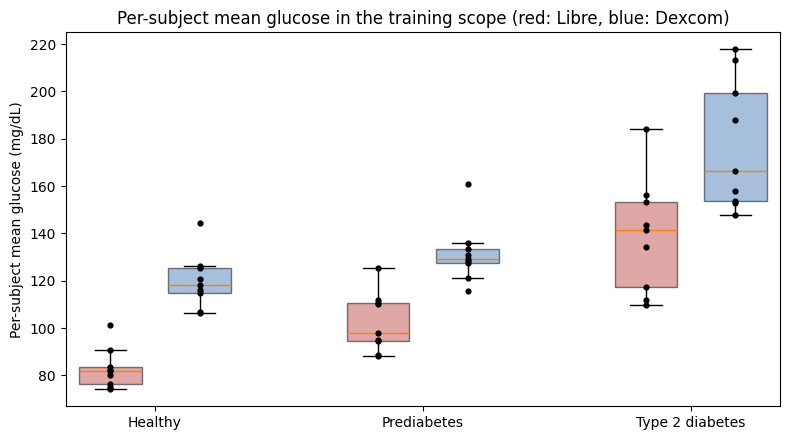

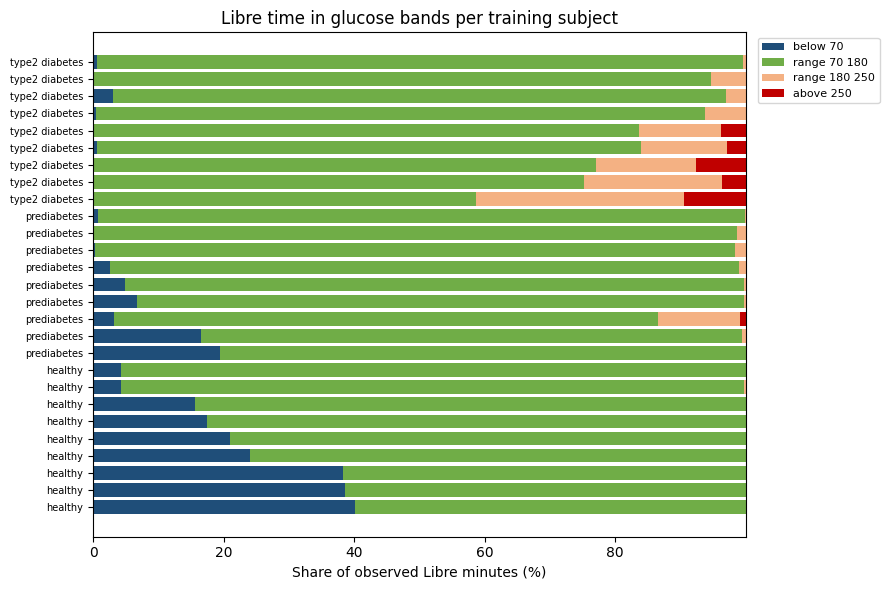

In [6]:
# Figure: per-subject mean glucose by metabolic status for each device.
fig, axis = plt.subplots(figsize=(8, 4.5))
device_labels = {"libre_gl": "Libre", "dexcom_gl": "Dexcom"}
positions, box_data, colors = [], [], []
for group_index, status in enumerate(status_order):
    for device_index, device in enumerate(["libre_gl", "dexcom_gl"]):
        values = subject_glucose.loc[
            (subject_glucose["metabolic_status"] == status) & (subject_glucose["device"] == device), "mean"
        ].dropna()
        positions.append(group_index * 3 + device_index)
        box_data.append(values.values)
        colors.append("#C0504D" if device == "libre_gl" else "#4F81BD")
boxes = axis.boxplot(box_data, positions=positions, widths=0.7, patch_artist=True, showfliers=False)
for patch, color in zip(boxes["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
for position, values in zip(positions, box_data):
    axis.scatter(np.full(len(values), position), values, s=12, color="black", zorder=3)
axis.set_xticks([0.5, 3.5, 6.5])
axis.set_xticklabels(["Healthy", "Prediabetes", "Type 2 diabetes"])
axis.set_ylabel("Per-subject mean glucose (mg/dL)")
axis.set_title("Per-subject mean glucose in the training scope (red: Libre, blue: Dexcom)")
fig.tight_layout()
fig.savefig(FORECAST_DIR / "eda_subject_mean_glucose.png", dpi=150, metadata=FIGURE_METADATA)
plt.show()

# Figure: per-subject time in glucose bands for Libre, grouped by metabolic status.
libre_bands = subject_glucose.loc[subject_glucose["device"] == "libre_gl"].copy()
libre_bands["status_rank"] = libre_bands["metabolic_status"].map({s: i for i, s in enumerate(status_order)})
libre_bands = libre_bands.sort_values(["status_rank", "pct_range_70_180"]).reset_index(drop=True)
band_columns = ["pct_below_70", "pct_range_70_180", "pct_range_180_250", "pct_above_250"]
band_colors = ["#1F4E79", "#70AD47", "#F4B183", "#C00000"]
fig, axis = plt.subplots(figsize=(9, 6))
left = np.zeros(len(libre_bands))
for column, color in zip(band_columns, band_colors):
    axis.barh(np.arange(len(libre_bands)), libre_bands[column], left=left, color=color,
              label=column.replace("pct_", "").replace("_", " "))
    left += libre_bands[column].to_numpy()
axis.set_yticks(np.arange(len(libre_bands)))
axis.set_yticklabels(libre_bands["metabolic_status"].str.replace("_", " "), fontsize=7)
axis.set_xlabel("Share of observed Libre minutes (%)")
axis.set_title("Libre time in glucose bands per training subject")
axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
fig.tight_layout()
fig.savefig(FORECAST_DIR / "eda_libre_time_in_bands.png", dpi=150, metadata=FIGURE_METADATA)
plt.show()

Band percentages use each subject's observed published minutes as the denominator; group summaries are across training subjects. Published glucose values are the released post-processed 1-minute series rather than native sensor samples.

                       count    25%    50%    75%
device    lag_minutes                            
dexcom_gl 1             27.0  0.999  0.999  1.000
          5             27.0  0.977  0.986  0.990
          15            27.0  0.851  0.900  0.931
          30            27.0  0.635  0.734  0.810
          60            27.0  0.388  0.508  0.585
          120           27.0  0.067  0.110  0.183
          240           27.0 -0.112 -0.014  0.072
libre_gl  1             27.0  1.000  1.000  1.000
          5             27.0  0.989  0.992  0.995
          15            27.0  0.914  0.932  0.957
          30            27.0  0.734  0.782  0.852
          60            27.0  0.471  0.538  0.617
          120           27.0  0.099  0.165  0.266
          240           27.0 -0.101  0.002  0.081


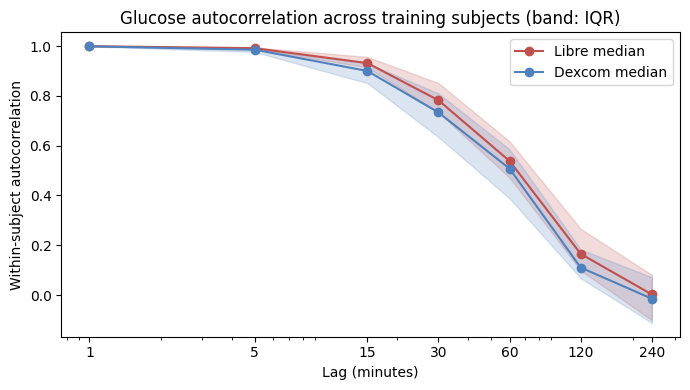

In [7]:
# Within-subject glucose autocorrelation at fixed minute lags on the contiguous training grid.
ACF_LAGS_MINUTES = [1, 5, 15, 30, 60, 120, 240]
acf_rows = []
for subject, frame in aligned.groupby("subject"):
    for device in ["libre_gl", "dexcom_gl"]:
        series = frame[device].reset_index(drop=True)
        for lag in ACF_LAGS_MINUTES:
            lagged = series.shift(-lag)
            pair_mask = series.notna() & lagged.notna()
            acf_rows.append({
                "subject": subject,
                "device": device,
                "lag_minutes": lag,
                "n_pairs": int(pair_mask.sum()),
                "autocorrelation": round(series[pair_mask].corr(lagged[pair_mask]), 4) if pair_mask.sum() > 2 else np.nan,
            })
subject_acf = pd.DataFrame(acf_rows)

acf_summary = (
    subject_acf.groupby(["device", "lag_minutes"])["autocorrelation"]
    .describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]]
    .round(3)
)
print(acf_summary.to_string())

fig, axis = plt.subplots(figsize=(7, 4))
for device, color in [("libre_gl", "#C0504D"), ("dexcom_gl", "#4F81BD")]:
    stats = subject_acf.loc[subject_acf["device"] == device].groupby("lag_minutes")["autocorrelation"]
    median, q25, q75 = stats.median(), stats.quantile(0.25), stats.quantile(0.75)
    axis.plot(median.index, median.values, marker="o", color=color, label=f"{device_labels[device]} median")
    axis.fill_between(median.index, q25.values, q75.values, color=color, alpha=0.2)
axis.set_xscale("log")
axis.set_xticks(ACF_LAGS_MINUTES)
axis.set_xticklabels([str(lag) for lag in ACF_LAGS_MINUTES])
axis.set_xlabel("Lag (minutes)")
axis.set_ylabel("Within-subject autocorrelation")
axis.set_title("Glucose autocorrelation across training subjects (band: IQR)")
axis.legend()
fig.tight_layout()
fig.savefig(FORECAST_DIR / "eda_glucose_autocorrelation.png", dpi=150, metadata=FIGURE_METADATA)
plt.show()

Short-lag autocorrelations are inflated by the released linear interpolation (Libre native cadence: 15 min; Dexcom: 5 min), so minute-level pairs should not be interpreted as independent observations.

       paired_fraction_of_grid  mean_difference_dexcom_minus_libre  sd_difference  pearson_r_same_minute  best_dexcom_lag_minutes
count                   27.000                              27.000         27.000                 27.000                   27.000
mean                     0.984                              34.894         17.906                  0.738                    2.519
std                      0.048                              13.423          7.122                  0.169                   12.186
min                      0.745                              16.654         11.399                  0.371                  -30.000
25%                      0.991                              25.005         13.552                  0.631                    3.000
50%                      0.992                              34.352         16.704                  0.779                    5.000
75%                      0.995                              41.372         19.215         

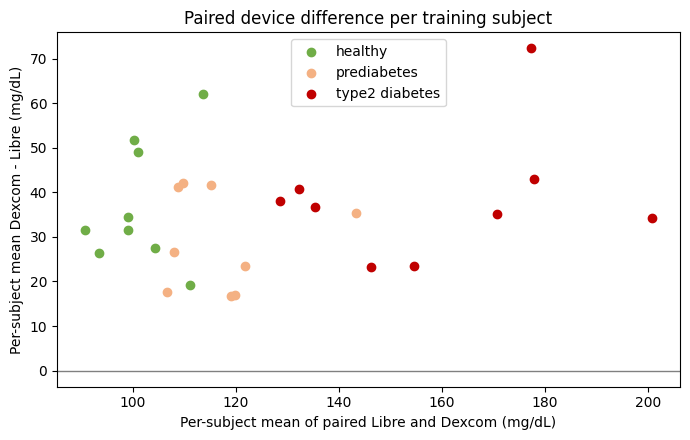

In [8]:
# Libre-Dexcom comparison restricted to minutes where both devices have published values.
CROSS_LAGS_MINUTES = list(range(-30, 31))
device_rows, cross_rows = [], []
for subject, frame in aligned.groupby("subject"):
    paired = frame.loc[frame["libre_gl"].notna() & frame["dexcom_gl"].notna()]
    difference = paired["dexcom_gl"] - paired["libre_gl"]
    device_rows.append({
        "subject": subject,
        "paired_minutes": len(paired),
        "paired_fraction_of_grid": round(len(paired) / len(frame), 4),
        "libre_mean_paired": round(paired["libre_gl"].mean(), 3),
        "dexcom_mean_paired": round(paired["dexcom_gl"].mean(), 3),
        "mean_difference_dexcom_minus_libre": round(difference.mean(), 3),
        "sd_difference": round(difference.std(ddof=1), 3),
        "median_absolute_difference": round(difference.abs().median(), 3),
        "pearson_r_same_minute": round(paired["libre_gl"].corr(paired["dexcom_gl"]), 4),
    })
    libre = frame["libre_gl"].reset_index(drop=True)
    dexcom = frame["dexcom_gl"].reset_index(drop=True)
    for lag in CROSS_LAGS_MINUTES:
        # Positive lag compares Libre at t with Dexcom at t + lag minutes.
        shifted = dexcom.shift(-lag)
        mask = libre.notna() & shifted.notna()
        cross_rows.append({"subject": subject, "lag_minutes": lag,
                           "correlation": libre[mask].corr(shifted[mask])})

device_pairs = pd.DataFrame(device_rows)
device_pairs["metabolic_status"] = device_pairs["subject"].map(metabolic_status)
cross_correlation = pd.DataFrame(cross_rows)
best_lag = cross_correlation.loc[cross_correlation.groupby("subject")["correlation"].idxmax(), ["subject", "lag_minutes"]]
device_pairs = device_pairs.merge(best_lag.rename(columns={"lag_minutes": "best_dexcom_lag_minutes"}), on="subject")

print(device_pairs[["paired_fraction_of_grid", "mean_difference_dexcom_minus_libre", "sd_difference",
                    "pearson_r_same_minute", "best_dexcom_lag_minutes"]].describe().round(3).to_string())
print(device_pairs.groupby("metabolic_status")["mean_difference_dexcom_minus_libre"].agg(["count", "median"])
      .reindex(status_order).round(2).to_string())

fig, axis = plt.subplots(figsize=(7, 4.5))
for status, color in zip(status_order, ["#70AD47", "#F4B183", "#C00000"]):
    group = device_pairs.loc[device_pairs["metabolic_status"] == status]
    level = (group["libre_mean_paired"] + group["dexcom_mean_paired"]) / 2
    axis.scatter(level, group["mean_difference_dexcom_minus_libre"], color=color, label=status.replace("_", " "))
axis.axhline(0, color="grey", linewidth=1)
axis.set_xlabel("Per-subject mean of paired Libre and Dexcom (mg/dL)")
axis.set_ylabel("Per-subject mean Dexcom - Libre (mg/dL)")
axis.set_title("Paired device difference per training subject")
axis.legend()
fig.tight_layout()
fig.savefig(FORECAST_DIR / "eda_device_difference.png", dpi=150, metadata=FIGURE_METADATA)
plt.show()

Differences and correlations use only minutes with published values from both devices. The best-lag shift (\(-30\) to \(+30\) min) is descriptive only; agreement statistics do not imply device interchangeability.

       heart_rate_bpm_observed_fraction  activity_calories_per_minute_observed_fraction  activity_met_observed_fraction  activity_intensity_raw_observed_fraction  steps_raw_observed_fraction
count                            27.000                                            27.0                          27.000                                    27.000                         27.0
mean                              0.926                                             1.0                           0.667                                     0.333                          0.0
50%                               0.985                                             1.0                           1.000                                     0.000                          0.0
min                               0.516                                             1.0                           0.000                                     0.000                          0.0
max                               1.000      

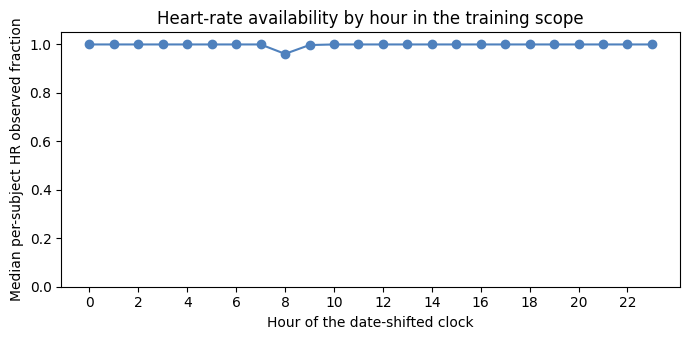

In [9]:
# Activity availability within the training scope, restricted to published source rows.
activity_columns = [
    "subject", "timestamp", "is_published_source_row", "heart_rate_bpm",
    "activity_calories_per_minute", "activity_met", "activity_intensity_raw", "steps_raw",
]
activity = pd.read_parquet(CLEAN_DIR / "activity_canonical.parquet", columns=activity_columns)
activity = activity.merge(aligned[["subject", "timestamp", "libre_gl"]], on=["subject", "timestamp"], how="inner")
activity = activity.loc[activity["is_published_source_row"]].reset_index(drop=True)

activity_fields = ["heart_rate_bpm", "activity_calories_per_minute", "activity_met",
                   "activity_intensity_raw", "steps_raw"]
activity_rows = []
for subject, frame in activity.groupby("subject"):
    row = {"subject": subject, "published_rows": len(frame)}
    for field in activity_fields:
        row[f"{field}_observed_fraction"] = round(frame[field].notna().mean(), 4)
    # Observed background: Libre level when heart rate is observed versus missing (same subject).
    hr_observed = frame["heart_rate_bpm"].notna()
    row["libre_mean_hr_observed"] = round(frame.loc[hr_observed, "libre_gl"].mean(), 3)
    row["libre_mean_hr_missing"] = round(frame.loc[~hr_observed, "libre_gl"].mean(), 3)
    row["minutes_hr_missing"] = int((~hr_observed).sum())
    activity_rows.append(row)

activity_missingness = pd.DataFrame(activity_rows)
activity_missingness["metabolic_status"] = activity_missingness["subject"].map(metabolic_status)
activity_missingness["libre_difference_hr_missing_minus_observed"] = (
    activity_missingness["libre_mean_hr_missing"] - activity_missingness["libre_mean_hr_observed"]
).round(3)

# Heart-rate availability by hour of the (date-shifted) clock, averaged within subject first.
activity["clock_hour"] = activity["timestamp"].dt.hour
hourly_hr = (
    activity.assign(hr_observed=activity["heart_rate_bpm"].notna())
    .groupby(["subject", "clock_hour"])["hr_observed"].mean()
    .groupby("clock_hour").median()
)

print(activity_missingness[[f"{field}_observed_fraction" for field in activity_fields]].describe()
      .loc[["count", "mean", "50%", "min", "max"]].round(3).to_string())
eligible = activity_missingness["minutes_hr_missing"] >= 60
print(f"Subjects with >= 60 HR-missing published minutes: {int(eligible.sum())} of {len(activity_missingness)}")
print(activity_missingness.loc[eligible, "libre_difference_hr_missing_minus_observed"].describe().round(2).to_string())

fig, axis = plt.subplots(figsize=(7, 3.5))
axis.plot(hourly_hr.index, hourly_hr.values, marker="o", color="#4F81BD")
axis.set_ylim(0, 1.05)
axis.set_xticks(range(0, 24, 2))
axis.set_xlabel("Hour of the date-shifted clock")
axis.set_ylabel("Median per-subject HR observed fraction")
axis.set_title("Heart-rate availability by hour in the training scope")
fig.tight_layout()
fig.savefig(FORECAST_DIR / "eda_hr_availability_by_hour.png", dpi=150, metadata=FIGURE_METADATA)
plt.show()

Coverage denominators use published source rows in scope; missing activity is unobserved, not rest or zero. Clock-hour summaries use date-shifted timestamps and are descriptive only.

In [10]:
# Meal-log availability within the training scope; absence of a log does not prove absence of eating.
meal_events = pd.read_parquet(CLEAN_DIR / "meal_events.parquet", columns=[
    "subject", "timestamp", "meal_event_id", "meal_type_normalized",
    "meal_calories", "carbs", "protein", "fat", "fiber", "has_complete_core_nutrition",
])
meal_events = meal_events.merge(eda_scope[["subject", "scope_start", "scope_end"]], on="subject", how="inner")
meal_events = meal_events.loc[
    meal_events["timestamp"].between(meal_events["scope_start"], meal_events["scope_end"])
].drop(columns=["scope_start", "scope_end"]).sort_values(["subject", "timestamp"]).reset_index(drop=True)
assert set(meal_events["subject"]) <= training_subjects

# Calendar days are taken from the date-shifted clock and used only as descriptive logging bins.
grid_days = aligned.assign(day=aligned["timestamp"].dt.normalize()).groupby("subject")["day"].nunique()
meal_days = meal_events.assign(day=meal_events["timestamp"].dt.normalize()).groupby("subject")["day"].nunique()

meal_logging = pd.DataFrame({"subject": sorted(training_subjects)})
meal_logging["scope_days_touched"] = meal_logging["subject"].map(grid_days)
meal_logging["days_with_logged_meal"] = meal_logging["subject"].map(meal_days).fillna(0).astype(int)
counts = meal_events.groupby(["subject", "meal_type_normalized"]).size().unstack(fill_value=0)
for meal_type in ["Breakfast", "Lunch", "Dinner", "Snack"]:
    meal_logging[f"n_{meal_type.lower()}"] = meal_logging["subject"].map(
        counts[meal_type] if meal_type in counts.columns else pd.Series(dtype=int)
    ).fillna(0).astype(int)
meal_logging["n_meal_events"] = meal_logging["subject"].map(meal_events.groupby("subject").size()).fillna(0).astype(int)
meal_logging["meal_events_per_touched_day"] = (meal_logging["n_meal_events"] / meal_logging["scope_days_touched"]).round(3)
meal_logging["complete_core_nutrition_fraction"] = meal_logging["subject"].map(
    meal_events.groupby("subject")["has_complete_core_nutrition"].mean()
).round(4)
meal_logging["metabolic_status"] = meal_logging["subject"].map(metabolic_status)

print(f"Meal events in the training scope: {len(meal_events):,} across {meal_events['subject'].nunique()} subjects")
print(meal_events["meal_type_normalized"].value_counts().to_string())
print(meal_logging[["scope_days_touched", "days_with_logged_meal", "n_meal_events",
                    "meal_events_per_touched_day", "complete_core_nutrition_fraction"]].describe().round(3).to_string())
print(meal_logging.groupby("metabolic_status")["meal_events_per_touched_day"].agg(["count", "median"])
      .reindex(status_order).round(3).to_string())

Meal events in the training scope: 659 across 27 subjects
meal_type_normalized
Dinner       182
Lunch        177
Breakfast    161
Snack        139
       scope_days_touched  days_with_logged_meal  n_meal_events  meal_events_per_touched_day  complete_core_nutrition_fraction
count              27.000                 27.000         27.000                       27.000                              27.0
mean                7.370                  6.963         24.407                        3.313                               1.0
std                 0.565                  0.587          6.110                        0.825                               0.0
min                 7.000                  6.000         12.000                        1.714                               1.0
25%                 7.000                  7.000         19.500                        2.714                               1.0
50%                 7.000                  7.000         25.000                        3.25

Calendar days are defined on the date-shifted clock; a day without a logged meal does not establish that no food was eaten.

In [11]:
# Exploratory post-meal Libre summaries anchored at each logged meal event.
PRE_MINUTES, POST_MINUTES = 30, 120
libre_by_subject = {subject: frame.set_index("timestamp")["libre_gl"] for subject, frame in aligned.groupby("subject")}
scope_bounds = eda_scope.set_index("subject")[["scope_start", "scope_end"]]
offsets = np.arange(-PRE_MINUTES, POST_MINUTES + 1)

response_rows, trajectory_rows = [], []
for subject, events in meal_events.groupby("subject"):
    libre = libre_by_subject[subject]
    event_times = events["timestamp"].to_numpy()
    for event in events.itertuples(index=False):
        t0 = event.timestamp
        window_start = t0 - pd.Timedelta(minutes=PRE_MINUTES)
        window_end = t0 + pd.Timedelta(minutes=POST_MINUTES)
        inside_scope = (window_start >= scope_bounds.loc[subject, "scope_start"]) and\
                       (window_end <= scope_bounds.loc[subject, "scope_end"])
        later_events = ((event_times > np.datetime64(t0)) & (event_times <= np.datetime64(window_end))).sum()
        row = {
            "subject": subject, "meal_event_id": event.meal_event_id, "timestamp": t0,
            "meal_type_normalized": event.meal_type_normalized, "carbs": event.carbs,
            "protein": event.protein, "fat": event.fat, "fiber": event.fiber,
            "meal_calories": event.meal_calories, "window_inside_scope": inside_scope,
            "other_meal_events_within_post_window": int(later_events),
        }
        if inside_scope:
            window = libre.reindex(pd.date_range(window_start, window_end, freq="min"))
            post = window.loc[t0:window_end]
            baseline = window.loc[t0]
            row["post_window_complete"] = bool(post.notna().all()) and pd.notna(baseline)
            if row["post_window_complete"]:
                increment = post - baseline
                row.update({
                    "baseline_libre": baseline,
                    "peak_increment": increment.max(),
                    "minutes_to_peak": int(np.argmax(increment.to_numpy())),
                    "mean_increment_0_120": round(increment.mean(), 4),
                    "increment_at_60": increment.iloc[60],
                    "increment_at_120": increment.iloc[120],
                })
                if row["other_meal_events_within_post_window"] == 0:
                    values = (window - baseline).to_numpy()
                    for offset, value in zip(offsets, values):
                        trajectory_rows.append({"subject": subject, "meal_type_normalized": event.meal_type_normalized,
                                                "offset_minutes": int(offset), "increment": value})
        else:
            row["post_window_complete"] = False
        response_rows.append(row)

meal_responses = pd.DataFrame(response_rows)
meal_responses["is_isolated_complete"] = (
    meal_responses["post_window_complete"] & meal_responses["other_meal_events_within_post_window"].eq(0)
)
isolated = meal_responses.loc[meal_responses["is_isolated_complete"]]

# Aggregate within subject first, then describe across subjects.
subject_meal_response = (
    isolated.groupby(["subject", "meal_type_normalized"])
    .agg(n_events=("meal_event_id", "size"), median_peak_increment=("peak_increment", "median"),
         median_minutes_to_peak=("minutes_to_peak", "median"), median_baseline=("baseline_libre", "median"))
    .reset_index()
)

# Within-subject rank association between logged nutrients and peak increment (hypothesis generating).
NUTRIENTS = ["carbs", "protein", "fat", "fiber", "meal_calories"]
MIN_EVENTS_FOR_ASSOCIATION = 8
association_rows = []
for subject, frame in isolated.groupby("subject"):
    for nutrient in NUTRIENTS:
        usable = frame[[nutrient, "peak_increment"]].dropna()
        if len(usable) >= MIN_EVENTS_FOR_ASSOCIATION and usable[nutrient].nunique() > 2:
            association_rows.append({
                "subject": subject, "nutrient": nutrient, "n_events": len(usable),
                "spearman_with_peak_increment": round(usable[nutrient].corr(usable["peak_increment"], method="spearman"), 4),
            })
nutrient_association = pd.DataFrame(association_rows)
nutrient_summary = nutrient_association.groupby("nutrient").agg(
    n_subjects=("subject", "nunique"),
    median_spearman=("spearman_with_peak_increment", "median"),
    n_positive=("spearman_with_peak_increment", lambda values: int((values > 0).sum())),
).reindex(NUTRIENTS).round(3)

print(f"Meal events with the full [-30, +120] min window inside the scope: {int(meal_responses['window_inside_scope'].sum())}")
print(f"Meal events with the full window inside the scope and a complete post-meal Libre window: {int(meal_responses['post_window_complete'].sum())}")
print(f"Meal events with a complete post-meal Libre window and no other logged meal in the post-meal window: {len(isolated)}")
print(subject_meal_response.groupby("meal_type_normalized")
      .agg(n_subjects=("subject", "nunique"), median_peak_increment=("median_peak_increment", "median"),
           median_minutes_to_peak=("median_minutes_to_peak", "median")).round(2).to_string())
print(nutrient_summary.to_string())

Meal events with the full [-30, +120] min window inside the scope: 649
Meal events with the full window inside the scope and a complete post-meal Libre window: 649
Meal events with a complete post-meal Libre window and no other logged meal in the post-meal window: 554
                      n_subjects  median_peak_increment  median_minutes_to_peak
meal_type_normalized                                                           
Breakfast                     27                  48.00                    60.0
Dinner                        26                  27.20                    53.0
Lunch                         27                  33.00                    57.0
Snack                         20                  23.32                    58.0
               n_subjects  median_spearman  n_positive
nutrient                                              
carbs                  27            0.409          27
protein                27            0.020          16
fat                    27      

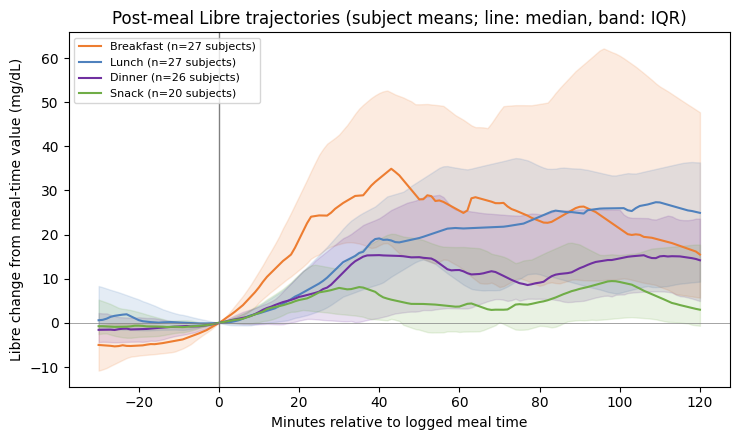

In [12]:
# Mean post-meal Libre increment: averaged within subject, then across subjects.
meal_trajectories = (
    pd.DataFrame(trajectory_rows)
    .groupby(["subject", "meal_type_normalized", "offset_minutes"])["increment"].mean()
    .round(4).reset_index()
)
fig, axis = plt.subplots(figsize=(7.5, 4.5))
for meal_type, color in zip(["Breakfast", "Lunch", "Dinner", "Snack"], ["#ED7D31", "#4F81BD", "#7030A0", "#70AD47"]):
    subset = meal_trajectories.loc[meal_trajectories["meal_type_normalized"] == meal_type]
    if subset.empty:
        continue
    by_offset = subset.groupby("offset_minutes")["increment"]
    n_subjects = subset["subject"].nunique()
    axis.plot(by_offset.median().index, by_offset.median().values, color=color, label=f"{meal_type} (n={n_subjects} subjects)")
    axis.fill_between(by_offset.median().index, by_offset.quantile(0.25).values, by_offset.quantile(0.75).values,
                      color=color, alpha=0.15)
axis.axvline(0, color="grey", linewidth=1)
axis.axhline(0, color="grey", linewidth=0.5)
axis.set_xlabel("Minutes relative to logged meal time")
axis.set_ylabel("Libre change from meal-time value (mg/dL)")
axis.set_title("Post-meal Libre trajectories (subject means; line: median, band: IQR)")
axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FORECAST_DIR / "eda_meal_trajectories.png", dpi=150, metadata=FIGURE_METADATA)
plt.show()

Each row represents one training subject; no significance testing is performed.

In [13]:
# Subject-level associations between background variables and per-subject mean Libre (hypothesis generating).
libre_level = subject_glucose.loc[subject_glucose["device"] == "libre_gl"].set_index("subject")["mean"]
static_variables = ["hba1c_lab_raw", "fasting_glucose_lab_mg_dl", "fasting_insulin_raw", "bmi", "age",
                    "triglycerides_mg_dl", "hdl_mg_dl"]
static_rows = []
for variable in static_variables:
    paired = pd.concat([bio.set_index("subject")[variable], libre_level], axis=1, join="inner").dropna()
    static_rows.append({
        "variable": variable,
        "n_subjects": len(paired),
        "spearman_with_subject_mean_libre": round(paired[variable].corr(paired["mean"], method="spearman"), 4),
    })
static_associations = pd.DataFrame(static_rows)

merge_coverage = pd.read_csv(CLEAN_DIR / "merge_coverage.csv")
merge_coverage = merge_coverage.loc[merge_coverage["subject"].isin(training_subjects)]
availability_registry = pd.read_csv(CLEAN_DIR / "availability_registry.csv")
gut_feature_count = int(availability_registry.loc[availability_registry["feature_group"].eq("gut_health_static"), "n_fields"].sum())
microbiome_feature_count = int(availability_registry.loc[availability_registry["feature_group"].eq("microbiome_static"), "n_fields"].sum())

print(static_associations.to_string(index=False))
print(f"Registered Gut Health fields: {gut_feature_count}; registered Microbiome fields: {microbiome_feature_count}")

                 variable  n_subjects  spearman_with_subject_mean_libre
            hba1c_lab_raw          27                            0.9105
fasting_glucose_lab_mg_dl          27                            0.9178
      fasting_insulin_raw          27                            0.4234
                      bmi          27                            0.2991
                      age          27                            0.3420
      triglycerides_mg_dl          27                            0.3911
                hdl_mg_dl          27                           -0.6057
Registered Gut Health fields: 22; registered Microbiome fields: 1979


Observation unit: subject (one row per training subject). With a few dozen subjects these rank correlations are hypothesis generating only; no significance testing is performed.

In [14]:
# Assemble candidate factors from the training-scope evidence and the availability registry.
n_training = len(training_subjects)
registry_scope = availability_registry.set_index("candidate_feature")["model_input_scope"]
registry_safety = availability_registry.set_index("candidate_feature")["safe_for_prediction_at_t"]
activity_coverage = activity_missingness.set_index("subject")
libre_acf = subject_acf.loc[subject_acf["device"] == "libre_gl"].groupby("lag_minutes")["autocorrelation"].median()
libre_means = subject_glucose.loc[subject_glucose["device"] == "libre_gl", "mean"]
hr_eligible = activity_missingness.loc[activity_missingness["minutes_hr_missing"] >= 60,
                                       "libre_difference_hr_missing_minus_observed"]
meal_type_peak = subject_meal_response.groupby("meal_type_normalized")["median_peak_increment"].median()
static_rho = static_associations.set_index("variable")


def subjects_with_activity(field: str) -> int:
    return int((activity_coverage[f"{field}_observed_fraction"] > 0).sum())


def nutrient_evidence(nutrient: str) -> str:
    row = nutrient_summary.loc[nutrient]
    return (f"within-subject Spearman with 2-h peak increment: median {row['median_spearman']:.2f}, "
            f"positive in {int(row['n_positive'])}/{int(row['n_subjects'])} subjects")


candidate_rows = [
    ("Glucose History", "libre_gl", "minute", n_training,
     f"median within-subject ACF {libre_acf.loc[30]:.2f} at 30 min and {libre_acf.loc[60]:.2f} at 60 min; "
     f"per-subject mean {libre_means.min():.0f}-{libre_means.max():.0f} mg/dL"),
    ("Glucose History", "dexcom_gl", "minute", int((device_pairs["paired_minutes"] > 0).sum()),
     f"median per-subject Dexcom minus Libre {device_pairs['mean_difference_dexcom_minus_libre'].median():.1f} mg/dL; "
     f"median same-minute r {device_pairs['pearson_r_same_minute'].median():.2f}; devices are not interchangeable"),
    ("Activity", "heart_rate_bpm", "minute", subjects_with_activity("heart_rate_bpm"),
     f"median observed fraction {activity_coverage['heart_rate_bpm_observed_fraction'].median():.2f}; "
     f"Libre difference (HR missing minus observed) median {hr_eligible.median():.1f} mg/dL over {len(hr_eligible)} subjects, "
     f"no consistent direction (IQR {hr_eligible.quantile(0.25):.1f} to {hr_eligible.quantile(0.75):.1f})"),
    ("Activity", "activity_calories_per_minute", "minute", subjects_with_activity("activity_calories_per_minute"),
     f"median observed fraction {activity_coverage['activity_calories_per_minute_observed_fraction'].median():.2f}"),
    ("Activity", "activity_met", "minute", subjects_with_activity("activity_met"),
     "available only for the MET schema; not interchangeable with Intensity"),
    ("Activity", "activity_intensity_raw", "minute", subjects_with_activity("activity_intensity_raw"),
     "available only for the Intensity schema; undocumented in the released dictionary"),
    ("Activity", "steps_raw", "minute", subjects_with_activity("steps_raw"),
     "undocumented field with very limited coverage"),
    ("Diet", "carbs", "meal event", int(nutrient_summary.loc["carbs", "n_subjects"]), nutrient_evidence("carbs")),
    ("Diet", "protein", "meal event", int(nutrient_summary.loc["protein", "n_subjects"]), nutrient_evidence("protein")),
    ("Diet", "fat", "meal event", int(nutrient_summary.loc["fat", "n_subjects"]), nutrient_evidence("fat")),
    ("Diet", "fiber", "meal event", int(nutrient_summary.loc["fiber", "n_subjects"]), nutrient_evidence("fiber")),
    ("Diet", "meal_calories", "meal event", int(nutrient_summary.loc["meal_calories", "n_subjects"]),
     nutrient_evidence("meal_calories")),
    ("Diet", "meal_type", "meal event", int(meal_events["subject"].nunique()),
     "median per-subject peak increment: " + ", ".join(f"{meal} {value:.0f}" for meal, value in meal_type_peak.items())
     + " mg/dL"),
    ("Diet", "amount_consumed", "meal event", int(meal_events["subject"].nunique()),
     "not available before meal completion; values above 100 unresolved"),
]
for variable in ["age", "gender", "bmi", "hba1c_lab_raw", "fasting_glucose_lab_mg_dl", "fasting_insulin_raw",
                 "triglycerides_mg_dl", "hdl_mg_dl"]:
    if variable in static_rho.index:
        evidence = (f"Spearman with per-subject mean Libre {static_rho.loc[variable, 'spearman_with_subject_mean_libre']:.2f} "
                    f"(n={int(static_rho.loc[variable, 'n_subjects'])} subjects)")
    else:
        evidence = "subject-level background variable; association not examined"
    candidate_rows.append(("Bio", f"bio__{variable}", "subject", int(bio[variable].notna().sum()), evidence))
candidate_rows.append(("Gut", "gut_health_scores", "subject", int(merge_coverage["gut_values_available"].sum()),
                       f"{gut_feature_count} ordinal scores; association not examined in the training-scope EDA"))
candidate_rows.append(("Microbiome", "microbiome_indicators", "subject",
                       int(merge_coverage["microbiome_values_available"].sum()),
                       f"{microbiome_feature_count} presence/absence indicators versus "
                       f"{int(merge_coverage['microbiome_values_available'].sum())} training subjects"))

candidate_factors = pd.DataFrame(candidate_rows, columns=[
    "feature_group", "candidate", "observation_level", "n_training_subjects_with_data", "training_eda_evidence",
])

GROUP_REGISTRY_ROWS = {"gut_health_scores": "gut_health_static", "microbiome_indicators": "microbiome_static"}


def registry_value(candidate: str, column: str) -> str:
    if candidate in GROUP_REGISTRY_ROWS:
        group_rows = availability_registry.loc[availability_registry["feature_group"] == GROUP_REGISTRY_ROWS[candidate], column]
        return group_rows.iloc[0]
    lookup = registry_scope if column == "model_input_scope" else registry_safety
    return lookup.get(candidate, "not_registered")


candidate_factors["registry_model_input_scope"] = [registry_value(c, "model_input_scope") for c in candidate_factors["candidate"]]
candidate_factors["registry_safe_for_prediction_at_t"] = [
    registry_value(c, "safe_for_prediction_at_t") for c in candidate_factors["candidate"]
]


def eda_status(row: pd.Series) -> str:
    if row["registry_safe_for_prediction_at_t"] == "no_before_meal_completion":
        return "excluded_not_available_at_prediction_time"
    if row["feature_group"] == "Microbiome":
        return "deferred_to_optional_extension"
    if row["candidate"] == "dexcom_gl":
        return "candidate_sensitivity_device"
    if row["n_training_subjects_with_data"] < n_training / 2:
        return "not_recommended_limited_coverage"
    if row["feature_group"] == "Gut":
        return "optional_small_supplement"
    if str(row["registry_model_input_scope"]).startswith("offline"):
        return "candidate_offline_analysis_only"
    if row["registry_model_input_scope"] == "candidate_only_with_explicit_availability_assumption":
        return "candidate_with_availability_assumption"
    return "candidate_for_ablation"


candidate_factors["eda_status"] = candidate_factors.apply(eda_status, axis=1)
print(candidate_factors[["feature_group", "candidate", "n_training_subjects_with_data", "eda_status"]].to_string(index=False))

  feature_group                      candidate  n_training_subjects_with_data                                eda_status
Glucose History                       libre_gl                             27                    candidate_for_ablation
Glucose History                      dexcom_gl                             27              candidate_sensitivity_device
       Activity                 heart_rate_bpm                             27                    candidate_for_ablation
       Activity   activity_calories_per_minute                             27                    candidate_for_ablation
       Activity                   activity_met                             18                    candidate_for_ablation
       Activity         activity_intensity_raw                              9          not_recommended_limited_coverage
       Activity                      steps_raw                              0          not_recommended_limited_coverage
           Diet                         

Candidate factors summarize training-scope coverage and prediction-time availability. They are hypotheses for model comparison, not validated predictors, importance rankings or causal effects.


In [15]:
# Persist the training-scope outputs consumed downstream: training_eda_scope and candidate_factors.
scope_summary.to_csv(FORECAST_DIR / "training_eda_scope.csv", index=False)
candidate_factors.to_csv(FORECAST_DIR / "candidate_factors.csv", index=False)

## Primary prediction task protocol

Define the target, history, horizon, origin stride and availability rules. The following sections construct eligible windows, assign splits and derive causal glucose features.


In [16]:
# Validate the target mapping and feature-availability requirements.
column_mapping = pd.read_csv(CLEAN_DIR / "column_mapping.csv")

assert {"raw_column_name", "canonical_column_name", "analytic_role"}.issubset(column_mapping.columns)
required_availability_columns = {
    "feature_group", "candidate_feature", "event_time_definition",
    "availability_time_definition", "safe_for_prediction_at_t",
    "model_input_scope", "offline_analysis_only", "leakage_boundary",
}
assert required_availability_columns.issubset(availability_registry.columns)

target_mappings = column_mapping.loc[column_mapping["canonical_column_name"].eq("libre_gl")]
assert not target_mappings.empty, "The canonical Libre target is absent from the column mapping."
required_availability_entries = {
    "libre_gl", "dexcom_gl", "amount_consumed", "meal_image_content",
    "heart_rate_bpm", "activity_calories_per_minute",
}
assert required_availability_entries.issubset(set(availability_registry["candidate_feature"]))

In [17]:
# Define the primary task geometry and availability rules.
task_protocol = {
    "schema_version": "1.0",
    "protocol_id": "primary_libre_120m_to_30m_stride5",
    "primary_task": {
        "task_id": "primary_libre_30min",
        "task_status": "primary",
        "target_device": "Libre",
        "target_field": "libre_gl",
        "target_unit": "mg/dL",
        "prediction_type": "single_future_point_glucose_forecasting",
        "history_minutes": 120,
        "history_interval": "[t - 120 minutes, t]",
        "forecast_horizon_minutes": 30,
        "origin_stride_minutes": 5,
        "grid_resolution_minutes": 1,
        "base_grid_artifact": "results/aligned_data/dynamic_aligned_1min.parquet",
    },
    "input_availability_policy": {
        "global_cutoff_rule": "An input may be used only if both its event time and its availability time are at or before origin time t.",
        "future_information_rule": "No value, aggregate, metadata, or preprocessing result that depends on times after t may enter the input.",
        "glucose_history": {
            "status": "conditional_strictly_historical_offline",
            "rule": "Released glucose values require timestamps at or before t; target-horizon glucose is excluded from input.",
        },
        "activity": {
            "status": "conditional_strictly_historical_offline",
            "rule": "Only activity minutes available by t may be used; future minutes, centered filters, completed-day summaries, and missing-as-zero substitutions are excluded.",
        },
        "meal_logs": {
            "status": "conditional_after_verified_record_creation",
            "rule": "Meal type and nutrients cannot be backfilled before the log existed; the released meal timestamp does not establish upload time.",
        },
        "amount_consumed": {
            "status": "not_available_before_verified_meal_completion",
            "rule": "Final Amount Consumed cannot be used before meal completion and cannot retrospectively rescale nutrients without a separate justified rule.",
        },
        "meal_photos": {
            "status": "offline_only_until_timing_verified",
            "rule": "Photo content requires verified capture, upload, and feature-extraction availability by t; paths and folder identities are excluded as predictors.",
        },
        "static_measurements": {
            "status": "conditional_or_offline_only",
            "rule": "Bio, Gut, and Microbiome results may enter only when result availability before the prediction period is established; later-returned results cannot be backfilled.",
        },
        "calendar_context": {
            "status": "shifted_clock_only",
            "rule": "Shifted calendar dates cannot represent real season, holiday, or calendar context.",
        },
        "identifiers_and_metadata": {
            "status": "excluded",
            "rule": "Subject identifiers, file paths, image paths, export indices, and source metadata are not ordinary predictive features.",
        },
    },
    "offline_interpretation": {
        "scope": "retrospective forecasting protocol on released, shifted, one-minute aligned data",
    },
    "sensitivity_candidates": [
        {
            "task_id": "sensitivity_horizon_60min",
            "change": {"forecast_horizon_minutes": 60},
            "status": "not_evaluated_in_protocol_definition",
        },
        {
            "task_id": "sensitivity_alternative_history",
            "change": {"history_minutes": "not_specified"},
            "status": "not_evaluated_in_protocol_definition",
        },
        {
            "task_id": "sensitivity_dexcom_target",
            "change": {"target_device": "Dexcom", "target_field": "dexcom_gl", "target_unit": "mg/dL"},
            "status": "not_evaluated_in_protocol_definition",
        },
    ],

}

# The serialized protocol is the downstream task contract.

# Persist one stable machine-readable protocol for the rest of the pipeline.
task_protocol_path = FORECAST_DIR / "task_protocol.json"
task_protocol_text = json.dumps(task_protocol, ensure_ascii=False, indent=2) + "\n"
task_protocol_path.write_text(task_protocol_text, encoding="utf-8")



The primary task predicts `Libre GL` at \(t+30\) minutes from information available by \(t\) within \([t-120,t]\), using five-minute origins on the released one-minute grid. Values are in mg/dL.


## Window and label construction

Construct timestamp-based windows and exact labels from the persisted primary protocol. The closed history interval requires finite, nonmissing published values at every grid point. Eligibility requires the entire history-to-target interval to lie in one inherited source segment, following the upstream gap-barrier rule for every source gap; first-failure exclusions are sequential.

In [18]:
# Read the target and structural provenance for window construction, without constructing predictors.
window_task = task_protocol["primary_task"]
window_task_id = window_task["task_id"]
window_target_field = window_task["target_field"]
window_grid_delta = pd.Timedelta(minutes=window_task["grid_resolution_minutes"])
window_history_delta = pd.Timedelta(minutes=window_task["history_minutes"])
window_horizon_delta = pd.Timedelta(minutes=window_task["forecast_horizon_minutes"])
window_stride_delta = pd.Timedelta(minutes=window_task["origin_stride_minutes"])
window_expected_points = int(window_history_delta / window_grid_delta) + 1

window_origin_field = f"{window_target_field}_value_origin"
window_dynamic = pd.read_parquet(PROJECT_ROOT / window_task["base_grid_artifact"], columns=[
    "subject", "timestamp", window_target_field, window_origin_field,
    "source_segment_id", "source_file", "source_row_index", "is_published_source_row",
    "is_inserted_grid_row", "has_project_interpolated_values",
]).sort_values(["subject", "timestamp"]).reset_index(drop=True)
window_segments = pd.read_csv(CLEAN_DIR / "time_segments.csv", parse_dates=["segment_start_time", "segment_end_time"])
window_gaps = pd.read_csv(CLEAN_DIR / "gap_intervals.csv", parse_dates=["previous_source_timestamp", "next_source_timestamp"])
print(f"History points (both endpoints included): {window_expected_points}; source segments: {len(window_segments):,}")

History points (both endpoints included): 121; source segments: 1,200


In [19]:
# Construct candidates by timestamp and apply sequential structural eligibility (implementation in src/windows.py).
window_candidates, sample_flow, window_manifest, window_exclusion_stages = build_windows(
    window_dynamic, window_segments, task_id=window_task_id, target_field=window_target_field,
    origin_field=window_origin_field, target_unit=window_task["target_unit"], grid_delta=window_grid_delta,
    history_delta=window_history_delta, horizon_delta=window_horizon_delta, stride_delta=window_stride_delta)
print(sample_flow.to_string(index=False))

            task_id  stage                                 rule  input_count  excluded_count  remaining_count
primary_libre_30min      0                    candidate_origins       141263               0           141263
primary_libre_30min      1          insufficient_history_extent       141263            1080           140183
primary_libre_30min      2        target_outside_subject_extent       140183             270           139913
primary_libre_30min      3      disallowed_source_discontinuity       139913            5299           134614
primary_libre_30min      4 incomplete_published_primary_history       134614              70           134544
primary_libre_30min      5                   target_unavailable       134544               5           134539
primary_libre_30min      6                     eligible_windows       134539               0           134539


In [20]:
# Assert exact timing and labels.
window_key = ["subject", "origin_time", "task_id"]
assert not window_manifest.duplicated(window_key).any()
assert window_manifest["target_time"].eq(window_manifest["origin_time"] + window_horizon_delta).all()
assert window_manifest["history_start_time"].eq(window_manifest["origin_time"] - window_history_delta).all()
assert window_manifest["history_end_time"].eq(window_manifest["origin_time"]).all()
assert len(window_manifest) + sample_flow["excluded_count"].sum() == len(window_candidates)

# Independently verify labels via exact subject/timestamp joins; no nearest match or filling.
window_label_check = window_manifest[["subject", "target_time", "target_value", "segment_id"]].merge(
    window_dynamic[["subject", "timestamp", window_target_field, "source_segment_id"]],
    left_on=["subject", "target_time"], right_on=["subject", "timestamp"], how="left", validate="many_to_one",
)
assert window_label_check["target_value"].eq(window_label_check[window_target_field]).all()
assert window_label_check["segment_id"].eq(window_label_check["source_segment_id"]).all()

# Check every eligible interval against upstream gaps, without consulting intermediate future glucose.
for gap in window_gaps.itertuples(index=False):
    crossing = window_manifest["subject"].eq(gap.subject) & window_manifest["history_start_time"].lt(gap.next_source_timestamp) & window_manifest["target_time"].gt(gap.previous_source_timestamp)
    assert not crossing.any(), "Eligible window overlaps an inherited source gap."

In [21]:
# Persist the eligible manifest, sequential flow, and rule provenance.
window_rules = {
    "rule_version": "strict_published_history_v1",
    "task_id": window_task_id,
    "primary_task_read_from_protocol": window_task,
    "history_interval": "closed at both ends: [origin - history_duration, origin]",
    "expected_history_points": window_expected_points,
    "origin_rule": "Per-subject date_range from first through last aligned timestamp at protocol stride; phase anchored to subject start, never reset by a gap. Origins in inserted rows are retained as candidates and rejected by continuity.",
    "continuity_rule": "Treat every source interval longer than one minute as a continuity boundary and retain >15, >60, and >1440 minute audit flags.",
    "continuity_implementation": "Entire closed history-start to target interval must lie within the origin's inherited subject/source segment. No source-gap tolerance.",
    "valid_history_value": "Finite, nonmissing published source value; no inserted grid point and no project interpolation. Native device anchor status remains unknown.",
    "target_rule": "Exact subject + target timestamp, finite nonmissing published value; no filling, interpolation, nearest match, or label repair.",
    "intermediate_horizon_values": "Not required to be nonmissing; only structural source continuity is checked between origin and target. These future values are never predictors.",
    "flow_accounting": "Sequential, first-failure exclusions in the saved stage order; later failures are not counted again.",
    "exclusion_order": [reason for reason, _ in window_exclusion_stages],
    "all_cohort_processing": "Fixed structural construction only; labels persisted without outcome-distribution or performance analysis; split-boundary eligibility is applied at split assignment.",
    "availability_policy": task_protocol["input_availability_policy"],
    "offline_interpretation": task_protocol["offline_interpretation"],
    "availability_limit": "History completeness certifies released source support, not verified live arrival by origin; unresolved arrival and publisher interpolation remain offline limitations.",
    "deferred": ["short-gap tolerance comparison", "fold assignments and split-boundary exclusion", "feature engineering and learned preprocessing"],
    "audit_only_columns": ["segment_id", "segment_start_time", "segment_end_time", "source_file", "origin_source_row_index", "target_source_row_index"],
}
window_manifest.to_parquet(FORECAST_DIR / "window_manifest.parquet", index=False)
sample_flow.to_csv(FORECAST_DIR / "sample_flow.csv", index=False)
(FORECAST_DIR / "window_construction_rules.json").write_text(json.dumps(window_rules, indent=2) + "\n", encoding="utf-8")

5133

Exclusion counts use the first failure only. Source continuity is required throughout history-to-target, while intervening forecast-period glucose values are not inputs or completeness requirements. Split-boundary eligibility remains for the split-assignment section below; no folds or features are constructed here.

## Temporal and subject-level splits

Assign admitted windows to two evaluation protocols. Within-subject Future Prediction requires the entire closed history-to-target support to lie in train \([\mathrm{start}, \mathrm{train\_end}]\), validation \((\mathrm{train\_end}, \mathrm{val\_end}]\), or test \((\mathrm{val\_end}, \mathrm{end}]\); crossing windows are excluded. Unseen-subject Generalization inherits each subject's primary assignment without resampling. Held-out subjects may supply causally available pre-origin history at prediction time, but their data cannot fit preprocessing or models.

In [22]:
# Use the task, admitted windows, and subject assignments for both evaluation protocols.
split_task = task_protocol["primary_task"]
split_scope = split_scope.rename(columns={"subject_id": "subject"})

# Structural window fields only; outcomes are neither needed nor inspected.
split_window_columns = ["task_id", "subject", "origin_time", "history_start_time", "history_end_time",
    "target_time", "segment_id", "source_file"]
split_windows = window_manifest[split_window_columns].copy()
split_sample_key = ["subject", "origin_time", "task_id"]
split_labels = ["train", "validation", "test"]
protocol_a_name = "Within-subject Future Prediction"
protocol_b_name = "Unseen-subject Generalization"

# Fail on incompatible upstream state instead of inventing a replacement split.
assert not split_scope["subject"].duplicated().any()
assert set(split_scope["protocol_b_group"]) <= {"train", "val", "test"}
assert not split_scope["protocol_b_group"].isna().any()
assert set(split_windows["subject"]) <= set(split_scope["subject"])
assert (split_scope["start_time"].lt(split_scope["protocol_a_train_end_time"])
    & split_scope["protocol_a_train_end_time"].lt(split_scope["protocol_a_val_end_time"])
    & split_scope["protocol_a_val_end_time"].lt(split_scope["end_time"])).all()
print("Primary subject assignments:", split_scope["protocol_b_group"].value_counts().to_dict())

Primary subject assignments: {'train': 27, 'val': 9, 'test': 9}


In [23]:
# Map each admitted window to both protocols, preserving its original identity.
fold_a, fold_b, fold_assignments = assign_splits(
    split_windows, split_scope, window_columns=split_window_columns, labels=split_labels,
    protocol_a_name=protocol_a_name, protocol_b_name=protocol_b_name, sample_key=split_sample_key)
split_counts = fold_assignments.groupby(["evaluation_protocol", "split"]).agg(
    windows=("task_id", "size"), subjects=("subject", "nunique")
).reset_index()
print(split_counts.to_string(index=False))


             evaluation_protocol      split  windows  subjects
   Unseen-subject Generalization       test    28322         9
   Unseen-subject Generalization      train    81958        27
   Unseen-subject Generalization validation    24259         9
Within-subject Future Prediction   excluded     2640        44
Within-subject Future Prediction       test    26269        45
Within-subject Future Prediction      train    79300        45
Within-subject Future Prediction validation    26330        45


In [24]:
# Validate split isolation and full-support window boundaries.
assert not fold_assignments.duplicated(["evaluation_protocol", *split_sample_key]).any()
assert fold_assignments["split"].isin([*split_labels, "excluded"]).all()
for frame in [fold_a, fold_b]:
    admitted = frame.loc[frame["admitted_to_split"]]
    lower_ok = np.where(admitted["partition_start_inclusive"].to_numpy(dtype=bool),
        admitted["history_start_time"].ge(admitted["partition_start_time"]),
        admitted["history_start_time"].gt(admitted["partition_start_time"]))
    assert lower_ok.all() and admitted["target_time"].le(admitted["partition_end_time"]).all()
split_subject_sets = {label: set(split_scope.loc[split_scope["protocol_b_group"].eq("val" if label == "validation" else label), "subject"]) for label in split_labels}
subject_overlap_count = sum(len(split_subject_sets[a] & split_subject_sets[b]) for a,b in [("train", "validation"), ("train", "test"), ("validation", "test")])
assert subject_overlap_count == 0
assert set.union(*split_subject_sets.values()) == set(split_scope["subject"])
assert fold_b.groupby("subject")["split"].nunique().eq(1).all()
for label in split_labels:
    assert set(fold_b.loc[fold_b["split"].eq(label), "subject"]) <= split_subject_sets[label]

In [25]:
# Save fold assignments and the split configuration required by downstream notebooks.
fold_assignments.to_parquet(FORECAST_DIR / "fold_assignments.parquet", index=False)
split_rules = {
    "version": "primary_scope_v1", "task_id": split_task["task_id"],
    "primary_assignment_source": {"path": "results/data_quality/split_scope_v1.csv"},
    "window_key": split_sample_key, "fold_key": ["evaluation_protocol", *split_sample_key],
    "temporal_partitions": {"train": "[start_time, protocol_a_train_end_time]", "validation": "(protocol_a_train_end_time, protocol_a_val_end_time]", "test": "(protocol_a_val_end_time, end_time]"},
    "support_rule": "The entire closed [history_start_time, target_time] must be in one temporal partition. Origins alone never determine admission.",
    "boundary_exclusion_reason": "temporal_boundary_crossing",
    "subject_rule": "Use protocol_b_group from primary split_scope_v1; normalize val to validation only.",
    "unseen_history_policy": "An unseen subject may supply causally available pre-origin history at prediction time. Only training subjects fit models, preprocessing, dimensionality reduction, and feature selection. Validation may guide model selection; test-subject windows, statistics, and history cannot guide fitting or tuning.",
    "preprocessing_policy": "Fit learned preprocessing separately on the appropriate training split of each protocol. Validation is for tuning and TEST does not guide fitting, tuning or selection.",
    "cross_protocol_policy": "Do not transfer learned statistics or choices from Protocol A data into Protocol B when those subjects are held out in Protocol B; shared exploration remains restricted to the common training range.",
}
(FORECAST_DIR / "split_rules.json").write_text(json.dumps(split_rules, indent=2) + "\n", encoding="utf-8")

1605

The checks above cover unassigned windows, partition violations, overlapping temporal supports, duplicate keys and subject-group intersections. Dependence within each split remains.


## Glucose history feature engineering

For history length \(H\), use lags at \(0,H/4,H/2,H\), plus trailing mean, population standard deviation and OLS slope over \([t-H/4,t]\) and \([t-H,t]\). These are geometric feature definitions; learned transformations must use admitted TRAIN rows only.


In [26]:
# --- Configure glucose-history feature definitions ---

feature_task = task_protocol["primary_task"]
feature_windows = window_manifest
feature_folds = fold_assignments[[
    "subject", "origin_time", "task_id", "evaluation_protocol", "split", "admitted_to_split",
    "history_start_time", "target_time",
]]
feature_key = ["subject", "origin_time", "task_id"]
feature_signal = feature_task["target_field"]
feature_origin_column = f"{feature_signal}_value_origin"
feature_cgm = window_dynamic[[
    "subject", "timestamp", feature_signal, "source_segment_id", "is_published_source_row",
    "is_inserted_grid_row", "has_project_interpolated_values", feature_origin_column,
]]
# --- Derive geometry-based feature scales fixed before model evaluation ---

feature_history = int(feature_task["history_minutes"])
feature_grid = int(feature_task["grid_resolution_minutes"])
feature_lags = [0, feature_history // 4, feature_history // 2, feature_history]
feature_durations = [feature_history // 4, feature_history]

registry_rows = []
for lag in feature_lags:
    registry_rows.append({"feature_name": f"glucose_lag_{lag}min", "feature_family": "current_glucose" if lag == 0 else "glucose_lag",
        "feature_type": "exact_timestamp_lag", "lag_minutes": lag, "duration_minutes": 0,
        "minimum_source_time_relative_to_origin_min": -lag, "maximum_source_time_relative_to_origin_min": -lag,
        "unit": feature_task["target_unit"], "calculation": f"G(t - {lag} minutes); exact subject/timestamp lookup"})
for duration in feature_durations:
    for statistic, family, formula, unit in [
        ("mean", "glucose_rolling", "Arithmetic mean of all published grid values in the closed trailing interval", feature_task["target_unit"]),
        ("std", "glucose_rolling", "Population standard deviation, ddof=0, of the closed trailing interval", feature_task["target_unit"]),
        ("slope", "glucose_trend", "OLS with intercept: sum((x-mean(x))*(G-mean(G)))/sum((x-mean(x))**2); x is elapsed minutes", feature_task["target_unit"] + "/min"),
    ]:
        registry_rows.append({"feature_name": f"glucose_{statistic}_{duration}min", "feature_family": family,
            "feature_type": "trailing_" + statistic, "lag_minutes": pd.NA, "duration_minutes": duration,
            "minimum_source_time_relative_to_origin_min": -duration, "maximum_source_time_relative_to_origin_min": 0,
            "unit": unit, "calculation": formula})
feature_registry = pd.DataFrame(registry_rows)
feature_registry["feature_group"] = "Glucose History"
feature_registry["source_signal"] = feature_signal
feature_registry["source_interval"] = feature_registry.apply(
    lambda row: f"[t{int(row['minimum_source_time_relative_to_origin_min']):+d}min, t{int(row['maximum_source_time_relative_to_origin_min']):+d}min], inclusive", axis=1)
feature_registry["allowed_as_predictor"] = True
feature_registry["leakage_rationale"] = "Every exact source timestamp lies in the closed history and is <= origin; no centered window, fill, interpolation, or whole-subject/day statistics."
feature_names = feature_registry["feature_name"].tolist()
assert feature_registry["minimum_source_time_relative_to_origin_min"].ge(-feature_history).all()
assert feature_registry["maximum_source_time_relative_to_origin_min"].le(0).all()
print(feature_registry[["feature_name", "feature_family", "minimum_source_time_relative_to_origin_min", "maximum_source_time_relative_to_origin_min", "unit"]].to_string(index=False))

        feature_name  feature_family  minimum_source_time_relative_to_origin_min  maximum_source_time_relative_to_origin_min      unit
    glucose_lag_0min current_glucose                                           0                                           0     mg/dL
   glucose_lag_30min     glucose_lag                                         -30                                         -30     mg/dL
   glucose_lag_60min     glucose_lag                                         -60                                         -60     mg/dL
  glucose_lag_120min     glucose_lag                                        -120                                        -120     mg/dL
  glucose_mean_30min glucose_rolling                                         -30                                           0     mg/dL
   glucose_std_30min glucose_rolling                                         -30                                           0     mg/dL
 glucose_slope_30min   glucose_trend                   

In [27]:
# Generate predictors using only exact historical timestamps, once per sample.
def extract_glucose_history(sample_geometry, historical_signal, registry, signal, grid_minutes):
    """Return raw features and source bounds; labels and split assignments are not inputs."""
    assert "target_value" not in sample_geometry.columns and "target_time" not in sample_geometry.columns
    minimum_offset = int(registry["minimum_source_time_relative_to_origin_min"].min())
    offsets = np.arange(minimum_offset, grid_minutes, grid_minutes, dtype=np.int64)
    output_parts = []
    for subject, geometry in sample_geometry.groupby("subject", sort=True):
        # Subject-specific lookup prevents cross-person matches at identical timestamps.
        source = historical_signal.loc[historical_signal["subject"].eq(subject)].set_index("timestamp").sort_index()
        origins = geometry["origin_time"].to_numpy(dtype="datetime64[ns]")
        query_times = origins[:, None] + offsets.astype("timedelta64[m]")[None, :]
        assert (query_times >= geometry["history_start_time"].to_numpy(dtype="datetime64[ns]")[:, None]).all()
        # Locate exact timestamps; array positions are lookup results, not assumed time offsets.
        positions = source.index.get_indexer(pd.DatetimeIndex(query_times.ravel()))
        if (positions < 0).any():
            raise ValueError("Admitted-history timestamp missing from the source grid.")
        rows = source.iloc[positions]
        values = rows[signal].to_numpy(dtype=float).reshape(query_times.shape)
        if not np.isfinite(values).all():
            raise ValueError("Admitted-history source contains missing/nonfinite values; no imputation is allowed.")
        out = geometry[["subject", "origin_time", "task_id"]].copy()
        out["predictor_min_source_time"] = query_times.min(axis=1)
        out["predictor_max_source_time"] = query_times.max(axis=1)
        for spec in registry.itertuples(index=False):
            low = int(spec.minimum_source_time_relative_to_origin_min)
            high = int(spec.maximum_source_time_relative_to_origin_min)
            used = (offsets >= low) & (offsets <= high)
            y = values[:, used]
            if spec.feature_type == "exact_timestamp_lag":
                calculated = y[:, 0]
            elif spec.feature_type == "trailing_mean":
                calculated = y.mean(axis=1)
            elif spec.feature_type == "trailing_std":
                calculated = y.std(axis=1, ddof=0)
            elif spec.feature_type == "trailing_slope":
                # Center fixed elapsed times within each trailing interval, not cohort glucose.
                x = offsets[used].astype(float)
                centered_x = x - x.mean()
                denominator = np.square(centered_x).sum()
                assert denominator > 0, "Slope is undefined without distinct source times."
                calculated = ((y - y.mean(axis=1, keepdims=True)) * centered_x).sum(axis=1) / denominator
            else:
                raise ValueError(f"Unsupported feature type: {spec.feature_type}")
            if not np.isfinite(calculated).all():
                raise ValueError(f"Nonfinite feature: {spec.feature_name}; no silent imputation or exclusion.")
            out[spec.feature_name] = calculated
        output_parts.append(out)
    return pd.concat(output_parts, ignore_index=True).sort_values(["subject", "origin_time", "task_id"]).reset_index(drop=True)

feature_geometry = feature_windows[["subject", "origin_time", "task_id", "history_start_time", "segment_id"]].copy()
glucose_history_x = extract_glucose_history(feature_geometry, feature_cgm, feature_registry, feature_signal, feature_grid)
assert len(glucose_history_x) == len(feature_windows)
assert glucose_history_x["predictor_max_source_time"].le(glucose_history_x["origin_time"]).all()
assert glucose_history_x["predictor_min_source_time"].eq(glucose_history_x["origin_time"] - pd.Timedelta(minutes=feature_history)).all()


In [28]:
# Attach labels after extracting causal features from structural window fields.
feature_metadata_columns = ["task_id", "subject", "origin_time", "history_start_time", "history_end_time", "target_time",
    "segment_id", "target_field", "target_unit"]

# This is the only label carry-through; the extraction function never receives y.
glucose_history_samples = feature_windows[[*feature_metadata_columns, "target_value"]].merge(
    glucose_history_x, on=feature_key, how="left", validate="one_to_one", indicator=True)
assert glucose_history_samples.pop("_merge").eq("both").all()
glucose_history_samples = glucose_history_samples.sort_values(feature_key).reset_index(drop=True)

assert set(feature_names) == set(glucose_history_samples.columns) - set(feature_metadata_columns) - {
    "target_value", "predictor_min_source_time", "predictor_max_source_time"}

# Prove every protocol can join the same unique features without changing assignments.
feature_fold_link = feature_folds.merge(glucose_history_samples[feature_key], on=feature_key, how="left", validate="many_to_one", indicator=True)
assert feature_fold_link.pop("_merge").eq("both").all()

# --- Persist the feature registry and glucose-history samples ---

feature_registry.to_csv(FORECAST_DIR / "feature_registry.csv", index=False)
glucose_history_samples.to_parquet(FORECAST_DIR / "glucose_history_samples.parquet", index=False)

Only registry-listed predictors belong in \(X\); identifiers, shifted timestamps, provenance and the label do not. Downstream preprocessing must use the selected protocol's admitted training rows only; validation may guide selection, and test must remain excluded from fitting, tuning and selection.